In [2]:
import sys
import numpy as np
import torch

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)

x = torch.tensor([1.0, 2.0, 3.0])
print("Tensor test:", x * 2)

Python: /Users/mac/Documents/MLInternship_week8/.venv/bin/python
NumPy: 1.26.4
PyTorch: 2.2.2
Tensor test: tensor([2., 4., 6.])


In [3]:

from pathlib import Path

# Locate the project folders
documents_dir = Path.home() / "Documents"
week7_dir = documents_dir / "MLInternship_week7"
week8_dir = Path.cwd()

print("Week 8 project:", week8_dir)
print("Week 7 project exists:", week7_dir.exists())

print("\nWeek 7 files:")

if week7_dir.exists():
    for path in sorted(week7_dir.rglob("*")):
        if path.is_file() and (
            path.suffix in {".ipynb", ".py", ".csv", ".json", ".pkl", ".joblib"}
        ):
            # Avoid listing files inside virtual environments
            if not any(part.startswith(".venv") for part in path.parts):
                print(path.relative_to(week7_dir))
else:
    print("Week 7 folder not found at the expected location.")

print("\nWeek 8 top-level items:")
for path in sorted(week8_dir.iterdir()):
    print(path.name)


Week 8 project: /Users/mac/Documents/MLInternship_week8/notebooks
Week 7 project exists: True

Week 7 files:
data/ycbv/test/000048/scene_camera.json
data/ycbv/test/000048/scene_gt.json
data/ycbv/test/000048/scene_gt_info.json
data/ycbv/test/000049/scene_camera.json
data/ycbv/test/000049/scene_gt.json
data/ycbv/test/000049/scene_gt_info.json
data/ycbv/test/000050/scene_camera.json
data/ycbv/test/000050/scene_gt.json
data/ycbv/test/000050/scene_gt_info.json
data/ycbv/test/000051/scene_camera.json
data/ycbv/test/000051/scene_gt.json
data/ycbv/test/000051/scene_gt_info.json
data/ycbv/test/000052/scene_camera.json
data/ycbv/test/000052/scene_gt.json
data/ycbv/test/000052/scene_gt_info.json
data/ycbv/test/000053/scene_camera.json
data/ycbv/test/000053/scene_gt.json
data/ycbv/test/000053/scene_gt_info.json
data/ycbv/test/000054/scene_camera.json
data/ycbv/test/000054/scene_gt.json
data/ycbv/test/000054/scene_gt_info.json
data/ycbv/test/000055/scene_camera.json
data/ycbv/test/000055/scene_gt.j

In [4]:

from pathlib import Path
import json
import pandas as pd

# Locate both projects
week8_root = Path.cwd().parent
week7_root = week8_root.parent / "MLInternship_week7"

print("Week 8 root:", week8_root)
print("Week 7 root:", week7_root)
print("Week 7 exists:", week7_root.exists())

# 1. Inspect important Week 7 result files
csv_files = [
    "results/feature_sample_metadata.csv",
    "results/validated_object_samples.csv",
    "results/final_classifier_comparison.csv",
    "results/object_class_distribution.csv",
]

for relative_path in csv_files:
    file_path = week7_root / relative_path
    print(f"\n{'=' * 65}")
    print(relative_path)

    if file_path.exists():
        df = pd.read_csv(file_path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("File not found.")

# 2. Inspect the Week 7 notebook structure
notebook_path = (
    week7_root / "notebooks" / "week7_classical_object_recognition.ipynb"
)

print(f"\n{'=' * 65}")
print("WEEK 7 NOTEBOOK")

if notebook_path.exists():
    with notebook_path.open("r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook["cells"]):
        source = "".join(cell.get("source", [])).strip()
        if not source:
            continue

        first_line = source.splitlines()[0]

        if cell["cell_type"] == "markdown":
            if first_line.startswith("#"):
                print(f"[Markdown {i}] {first_line[:150]}")
        else:
            print(f"[Code {i}] {first_line[:150]}")
else:
    print("Week 7 notebook not found.")


Week 8 root: /Users/mac/Documents/MLInternship_week8
Week 7 root: /Users/mac/Documents/MLInternship_week7
Week 7 exists: True

results/feature_sample_metadata.csv
Shape: (2700, 10)
Columns: ['scene_id', 'frame_id', 'instance_index', 'obj_id', 'class_name', 'rgb_path', 'mask_path', 'image_height', 'image_width', 'mask_pixels']
 scene_id  frame_id  instance_index  obj_id      class_name                                                                     rgb_path                                                                                  mask_path  image_height  image_width  mask_pixels
       48         1               0       1 Master Chef Can /Users/mac/Documents/MLInternship_week7/data/ycbv/test/000048/rgb/000001.png /Users/mac/Documents/MLInternship_week7/data/ycbv/test/000048/mask_visib/000001_000000.png           480          640        21729
       48         1               1       6   Tuna Fish Can /Users/mac/Documents/MLInternship_week7/data/ycbv/test/000048/rgb/000001.png

In [8]:
from pathlib import Path
import json
import pandas as pd

# Use the verified paths
documents_dir = Path.home() / "Documents"
week7_root = documents_dir / "MLInternship_week7"
week8_root = documents_dir / "MLInternship_week8"

results_dir = week7_root / "results"
notebook_path = (
    week7_root / "notebooks" / "week7_classical_object_recognition.ipynb"
)

print("Week 7 root:", week7_root)
print("Week 7 notebook exists:", notebook_path.exists())

# 1. Inspect CSV results
print("\n=== CSV FILE INVENTORY ===")

for path in sorted(results_dir.glob("*.csv")):
    try:
        df = pd.read_csv(path, nrows=3)
        print(
            f"{path.name} | columns={len(df.columns)} "
            f"| first columns={df.columns.tolist()[:8]}"
        )
    except Exception as exc:
        print(f"{path.name} | Could not inspect: {exc}")

# 2. Inspect feature extraction and model training code
print("\n=== WEEK 7 FEATURE / TRAINING CODE ===")

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "histogram", "hog", "feature", "train_test_split",
    "group", "scene", "fit(", "predict(", "classification",
    "cross_val", "out_of_fold", "to_csv", "joblib", "pickle"
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))
    if any(word in source.lower() for word in keywords):
        print(f"\n--- Cell {i} ---")
        print(source[:1800])
        if len(source) > 1800:
            print("... [truncated]")

# 3. Inspect Week 8 dataset scenes
print("\n=== WEEK 8 DATASET SCENES ===")

dataset_dir = week8_root / "data" / "ycbv" / "test"

if dataset_dir.exists():
    for scene_dir in sorted(dataset_dir.iterdir()):
        if not scene_dir.is_dir():
            continue

        rgb_dir = scene_dir / "rgb"
        gt_file = scene_dir / "scene_gt.json"

        rgb_count = (
            sum(1 for p in rgb_dir.glob("*.png"))
            if rgb_dir.exists() else 0
        )

        print(
            scene_dir.name,
            "| RGB images:", rgb_count,
            "| annotations:", gt_file.exists()
        )
else:
    print("Dataset directory not found:", dataset_dir)

Week 7 root: /Users/mac/Documents/MLInternship_week7
Week 7 notebook exists: True

=== CSV FILE INVENTORY ===
class_scene_coverage.csv | columns=5 | first columns=['obj_id', 'class_name', 'num_scenes', 'num_instances', 'scene_ids']
classifier_comparison_ranked.csv | columns=12 | first columns=['rank_by_macro_f1', 'feature_set', 'classifier', 'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1']
color_histogram_linear_svm_fast_predictions.csv | columns=3 | first columns=['scene_id', 'true_obj_id', 'predicted_obj_id']
color_histogram_linear_svm_fast_report.csv | columns=5 | first columns=['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support']
combined_color_hog_knn_predictions.csv | columns=3 | first columns=['scene_id', 'true_obj_id', 'predicted_obj_id']
combined_color_hog_knn_report.csv | columns=5 | first columns=['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support']
combined_color_hog_linear_svm_predictions.csv | columns=3 | first columns=['scene_

In [7]:
from pathlib import Path

current_dir = Path.cwd()

print("Current notebook directory:")
print(current_dir)

print("\nParent directories:")
print("Parent:", current_dir.parent)
print("Grandparent:", current_dir.parent.parent)

print("\nSearching for the Week 7 notebook:")

search_root = Path.home() / "Documents"

for path in search_root.glob(
    "**/week7_classical_object_recognition.ipynb"
):
    print(path)

print("\nChecking the expected Week 7 folder:")
week7_root = Path.home() / "Documents" / "MLInternship_week7"
print("Folder exists:", week7_root.exists())
print("Notebook exists:", (
    week7_root / "notebooks" / "week7_classical_object_recognition.ipynb"
).exists())

Current notebook directory:
/Users/mac/Documents/MLInternship_week8/notebooks

Parent directories:
Parent: /Users/mac/Documents/MLInternship_week8
Grandparent: /Users/mac/Documents

Searching for the Week 7 notebook:
/Users/mac/Documents/MLInternship_week7/notebooks/week7_classical_object_recognition.ipynb

Checking the expected Week 7 folder:
Folder exists: True
Notebook exists: True


In [9]:
from pathlib import Path
import json

documents_dir = Path.home() / "Documents"
week7_root = documents_dir / "MLInternship_week7"

notebook_path = (
    week7_root
    / "notebooks"
    / "week7_classical_object_recognition.ipynb"
)

# 1. Inspect the complete feature extraction cell
with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

print("=== WEEK 7 FEATURE EXTRACTION CELL ===")

source = "".join(notebook["cells"][21].get("source", []))
print("Cell length:", len(source), "characters")
print(source)

# 2. Look for saved numerical feature arrays or model files
print("\n=== POSSIBLE SAVED FEATURES / MODELS ===")

extensions = {".npy", ".npz", ".pkl", ".joblib", ".pt", ".pth"}

for folder in [week7_root / "results", week7_root / "models"]:
    if not folder.exists():
        print(f"\nFolder not found: {folder}")
        continue

    for path in sorted(folder.rglob("*")):
        if path.is_file() and path.suffix.lower() in extensions:
            print(path.relative_to(week7_root))

# 3. Check where Week 7's source images live
print("\n=== WEEK 7 DATA PATHS ===")

metadata_path = week7_root / "results" / "feature_sample_metadata.csv"

if metadata_path.exists():
    import pandas as pd

    metadata = pd.read_csv(metadata_path)
    print("Metadata samples:", len(metadata))
    print("Unique scenes:", metadata["scene_id"].nunique())
    print("Scene IDs:", sorted(metadata["scene_id"].unique()))

    print("\nExample RGB path:")
    print(metadata["rgb_path"].iloc[0])

    print("Example RGB exists:",
          Path(metadata["rgb_path"].iloc[0]).exists())

    print("\nExample mask path:")
    print(metadata["mask_path"].iloc[0])

    print("Example mask exists:",
          Path(metadata["mask_path"].iloc[0]).exists())

=== WEEK 7 FEATURE EXTRACTION CELL ===
Cell length: 7287 characters

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.feature import hog

# --------------------------------------------------
# 1. Feature extraction settings
# --------------------------------------------------
HIST_BINS = (16, 16, 16)
HOG_IMAGE_SIZE = (64, 64)  # width, height
HOG_PIXELS_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)

def extract_color_histogram(rgb_image, mask):
    """Extract a normalized HSV color histogram from masked pixels."""
    hsv = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2HSV)

    hist = cv2.calcHist(
        [hsv],
        [0, 1, 2],
        mask,
        HIST_BINS,
        [0, 180, 0, 256, 0, 256]
    )

    hist = cv2.normalize(hist, hist).flatten()
    return hist.astype(np.float32)


def extract_hog_features(rgb_image, mask):
    """Extract HOG features from the masked object on a neutral background."""
    gray = cv2.c

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd

WEEK7_ROOT = Path.home() / "Documents" / "MLInternship_week7"

features_path = WEEK7_ROOT / "results" / "handcrafted_features.npz"
metadata_path = WEEK7_ROOT / "results" / "feature_sample_metadata.csv"

# Allow loading the object array saved for scene groups.
with np.load(features_path, allow_pickle=True) as data:
    X_color = data["X_color"]
    X_hog = data["X_hog"]
    X_combined = data["X_combined"]
    y = data["y"]
    groups = data["groups"]

metadata = pd.read_csv(metadata_path)

print("=== FEATURE MATRIX CHECK ===")
print("Color features:", X_color.shape)
print("HOG features:", X_hog.shape)
print("Combined features:", X_combined.shape)
print("Labels:", y.shape)
print("Scene groups:", groups.shape)

print("\n=== DATA QUALITY ===")
print("Metadata rows:", len(metadata))
print(
    "All row counts aligned:",
    len(metadata) == len(y) == len(groups)
    == len(X_color) == len(X_hog) == len(X_combined)
)
print("All combined features finite:", bool(np.isfinite(X_combined).all()))

print("\n=== CLASS DISTRIBUTION ===")
class_counts = (
    metadata.groupby(["obj_id", "class_name"])
    .size()
    .reset_index(name="samples")
    .sort_values("obj_id")
)
print(class_counts.to_string(index=False))

print("\n=== SCENE COVERAGE ===")
scene_class_counts = metadata.groupby("scene_id")["obj_id"].nunique()
print(scene_class_counts.to_string())

print("\n=== LABEL ALIGNMENT ===")
print("Labels match metadata:",
      np.array_equal(y, metadata["obj_id"].to_numpy()))
print("Scene groups match metadata:",
      np.array_equal(groups, metadata["scene_id"].to_numpy()))

=== FEATURE MATRIX CHECK ===
Color features: (2700, 4096)
HOG features: (2700, 1764)
Combined features: (2700, 5860)
Labels: (2700,)
Scene groups: (2700,)

=== DATA QUALITY ===
Metadata rows: 2700
All row counts aligned: True
All combined features finite: True

=== CLASS DISTRIBUTION ===
 obj_id      class_name  samples
      1 Master Chef Can      300
      2     Cracker Box      225
      3       Sugar Box      375
      4 Tomato Soup Can      450
      6   Tuna Fish Can      300
      9 Potted Meat Can      225
     11    Pitcher Base      225
     12 Bleach Cleanser      300
     15     Power Drill      300

=== SCENE COVERAGE ===
scene_id
48    2
49    3
50    3
51    4
52    2
53    2
54    4
55    4
56    3
57    2
58    2
59    5

=== LABEL ALIGNMENT ===
Labels match metadata: True
Scene groups match metadata: False


In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

WEEK7_ROOT = Path.home() / "Documents" / "MLInternship_week7"

features_path = WEEK7_ROOT / "results" / "handcrafted_features.npz"
metadata_path = WEEK7_ROOT / "results" / "feature_sample_metadata.csv"

# Allow loading the object array saved for scene groups.
with np.load(features_path, allow_pickle=True) as data:
    X_color = data["X_color"]
    X_hog = data["X_hog"]
    X_combined = data["X_combined"]
    y = data["y"]
    groups = data["groups"]

metadata = pd.read_csv(metadata_path)

print("=== FEATURE MATRIX CHECK ===")
print("Color features:", X_color.shape)
print("HOG features:", X_hog.shape)
print("Combined features:", X_combined.shape)
print("Labels:", y.shape)
print("Scene groups:", groups.shape)

print("\n=== DATA QUALITY ===")
print("Metadata rows:", len(metadata))
print(
    "All row counts aligned:",
    len(metadata) == len(y) == len(groups)
    == len(X_color) == len(X_hog) == len(X_combined)
)
print("All combined features finite:", bool(np.isfinite(X_combined).all()))

print("\n=== CLASS DISTRIBUTION ===")
class_counts = (
    metadata.groupby(["obj_id", "class_name"])
    .size()
    .reset_index(name="samples")
    .sort_values("obj_id")
)
print(class_counts.to_string(index=False))

print("\n=== SCENE COVERAGE ===")
scene_class_counts = metadata.groupby("scene_id")["obj_id"].nunique()
print(scene_class_counts.to_string())

print("\n=== LABEL ALIGNMENT ===")
print("Labels match metadata:",
      np.array_equal(y, metadata["obj_id"].to_numpy()))
print("Scene groups match metadata:",
      np.array_equal(groups, metadata["scene_id"].to_numpy()))

=== FEATURE MATRIX CHECK ===
Color features: (2700, 4096)
HOG features: (2700, 1764)
Combined features: (2700, 5860)
Labels: (2700,)
Scene groups: (2700,)

=== DATA QUALITY ===
Metadata rows: 2700
All row counts aligned: True
All combined features finite: True

=== CLASS DISTRIBUTION ===
 obj_id      class_name  samples
      1 Master Chef Can      300
      2     Cracker Box      225
      3       Sugar Box      375
      4 Tomato Soup Can      450
      6   Tuna Fish Can      300
      9 Potted Meat Can      225
     11    Pitcher Base      225
     12 Bleach Cleanser      300
     15     Power Drill      300

=== SCENE COVERAGE ===
scene_id
48    2
49    3
50    3
51    4
52    2
53    2
54    4
55    4
56    3
57    2
58    2
59    5

=== LABEL ALIGNMENT ===
Labels match metadata: True
Scene groups match metadata: False


In [13]:
print("=== GROUP DATA TYPES ===")
print("groups dtype:", groups.dtype)
print("metadata scene_id dtype:", metadata["scene_id"].dtype)

print("\n=== FIRST 10 VALUES ===")
print("groups:   ", repr(groups[:10].tolist()))
print("metadata: ", repr(metadata["scene_id"].to_numpy()[:10].tolist()))

print("\n=== UNIQUE VALUES ===")
print("groups:", sorted(set(map(str, groups))))
print("metadata:", sorted(set(map(str, metadata["scene_id"]))))

print("\n=== ALIGNMENT TESTS ===")
groups_as_strings = np.asarray(groups).astype(str)
metadata_scenes_as_strings = metadata["scene_id"].astype(str).to_numpy()

print("Match after converting to strings:",
      np.array_equal(groups_as_strings, metadata_scenes_as_strings))

print("Same scene counts:",
      pd.Series(groups_as_strings).value_counts().sort_index().equals(
          metadata["scene_id"].astype(str).value_counts().sort_index()
      ))

=== GROUP DATA TYPES ===
groups dtype: object
metadata scene_id dtype: int64

=== FIRST 10 VALUES ===
groups:    ['000048', '000048', '000048', '000048', '000048', '000048', '000048', '000048', '000048', '000048']
metadata:  [48, 48, 48, 48, 48, 48, 48, 48, 48, 48]

=== UNIQUE VALUES ===
groups: ['000048', '000049', '000050', '000051', '000052', '000053', '000054', '000055', '000056', '000057', '000058', '000059']
metadata: ['48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59']

=== ALIGNMENT TESTS ===
Match after converting to strings: False
Same scene counts: False


In [14]:
# Normalize scene IDs to integers for comparison and splitting.
groups = np.asarray(groups).astype(str).astype(int)
metadata_scene_ids = metadata["scene_id"].to_numpy(dtype=int)

print("Groups dtype after normalization:", groups.dtype)
print("Metadata scene dtype:", metadata_scene_ids.dtype)

print("Scene IDs aligned:",
      np.array_equal(groups, metadata_scene_ids))

print("Unique scenes:", np.unique(groups))
print("Number of scenes:", len(np.unique(groups)))

Groups dtype after normalization: int64
Metadata scene dtype: int64
Scene IDs aligned: True
Unique scenes: [48 49 50 51 52 53 54 55 56 57 58 59]
Number of scenes: 12


In [15]:
# Count samples of each class in each scene.
scene_class_table = pd.crosstab(
    metadata["scene_id"],
    metadata["class_name"]
)

print("=== SAMPLES PER CLASS IN EACH SCENE ===")
print(scene_class_table.to_string())

print("\n=== NUMBER OF SCENES CONTAINING EACH CLASS ===")
class_scene_coverage = (scene_class_table > 0).sum(axis=0)
print(class_scene_coverage.sort_values().to_string())

print("\n=== CLASSES PRESENT IN EVERY SCENE ===")
print("No. of classes:", len(scene_class_table.columns))
print("Minimum scenes per class:", class_scene_coverage.min())

=== SAMPLES PER CLASS IN EACH SCENE ===
class_name  Bleach Cleanser  Cracker Box  Master Chef Can  Pitcher Base  Potted Meat Can  Power Drill  Sugar Box  Tomato Soup Can  Tuna Fish Can
scene_id                                                                                                                                        
48                        0            0               75             0                0            0          0                0             75
49                        0            0                0             0               75            0         75                0             75
50                        0           75                0             0                0           75          0               75              0
51                       75            0               75             0                0            0         75               75              0
52                        0            0                0            75                0  

In [16]:
import pandas as pd

scene_class_table = pd.crosstab(
    metadata["scene_id"],
    metadata["obj_id"]
).gt(0)

all_classes = set(metadata["obj_id"].unique())

print("=== LEAVE-ONE-SCENE-OUT FEASIBILITY ===")

for test_scene in sorted(metadata["scene_id"].unique()):
    train_scenes = metadata.loc[
        metadata["scene_id"] != test_scene, "scene_id"
    ].unique()

    train_classes = set(
        metadata.loc[
            metadata["scene_id"] != test_scene, "obj_id"
        ].unique()
    )

    test_classes = set(
        metadata.loc[
            metadata["scene_id"] == test_scene, "obj_id"
        ].unique()
    )

    unseen_test_classes = sorted(test_classes - train_classes)

    print(
        f"Test scene {test_scene}: "
        f"{len(test_classes)} test classes, "
        f"{len(unseen_test_classes)} unseen classes -> "
        f"{unseen_test_classes}"
    )

=== LEAVE-ONE-SCENE-OUT FEASIBILITY ===
Test scene 48: 2 test classes, 0 unseen classes -> []
Test scene 49: 3 test classes, 0 unseen classes -> []
Test scene 50: 3 test classes, 0 unseen classes -> []
Test scene 51: 4 test classes, 0 unseen classes -> []
Test scene 52: 2 test classes, 0 unseen classes -> []
Test scene 53: 2 test classes, 0 unseen classes -> []
Test scene 54: 4 test classes, 0 unseen classes -> []
Test scene 55: 4 test classes, 0 unseen classes -> []
Test scene 56: 3 test classes, 0 unseen classes -> []
Test scene 57: 2 test classes, 0 unseen classes -> []
Test scene 58: 2 test classes, 0 unseen classes -> []
Test scene 59: 5 test classes, 0 unseen classes -> []


In [17]:
import numpy as np

# Scene-level split: no scene is shared across sets.
test_scene = 59
validation_scene = 48

test_mask = groups == test_scene
validation_mask = groups == validation_scene
train_mask = ~(test_mask | validation_mask)

# Features: HSV color histograms only.
X_train = X_color[train_mask]
X_val = X_color[validation_mask]
X_test = X_color[test_mask]

y_train = y[train_mask]
y_val = y[validation_mask]
y_test = y[test_mask]

train_groups = groups[train_mask]
val_groups = groups[validation_mask]
test_groups = groups[test_mask]

print("=== SPLIT SIZES ===")
print("Train:", X_train.shape, "| samples:", len(y_train))
print("Validation:", X_val.shape, "| samples:", len(y_val))
print("Test:", X_test.shape, "| samples:", len(y_test))

print("\n=== SCENE SEPARATION ===")
print("Train scenes:", sorted(np.unique(train_groups).tolist()))
print("Validation scenes:", np.unique(val_groups).tolist())
print("Test scenes:", np.unique(test_groups).tolist())

print("\n=== CLASS COVERAGE ===")
train_classes = set(np.unique(y_train))
val_classes = set(np.unique(y_val))
test_classes = set(np.unique(y_test))

print("Classes in training:", sorted(train_classes))
print("Validation classes absent from train:", sorted(val_classes - train_classes))
print("Test classes absent from train:", sorted(test_classes - train_classes))

assert len(set(train_groups) & set(val_groups)) == 0
assert len(set(train_groups) & set(test_groups)) == 0
assert len(set(val_groups) & set(test_groups)) == 0
assert val_classes.issubset(train_classes)
assert test_classes.issubset(train_classes)

print("\nSplit checks passed.")

=== SPLIT SIZES ===
Train: (2175, 4096) | samples: 2175
Validation: (150, 4096) | samples: 150
Test: (375, 4096) | samples: 375

=== SCENE SEPARATION ===
Train scenes: [49, 50, 51, 52, 53, 54, 55, 56, 57, 58]
Validation scenes: [48]
Test scenes: [59]

=== CLASS COVERAGE ===
Classes in training: [1, 2, 3, 4, 6, 9, 11, 12, 15]
Validation classes absent from train: []
Test classes absent from train: []

Split checks passed.


In [18]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Use the same class mapping for all three splits.
class_ids = np.sort(np.unique(y_train))
class_to_index = {
    int(class_id): index
    for index, class_id in enumerate(class_ids)
}

print("Class-to-index mapping:")
for class_id, index in class_to_index.items():
    print(f"{class_id} -> {index}")

def encode_labels(labels):
    return np.array(
        [class_to_index[int(label)] for label in labels],
        dtype=np.int64
    )

# Convert features and encoded labels to PyTorch tensors.
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(encode_labels(y_train), dtype=torch.long)
y_val_tensor = torch.tensor(encode_labels(y_val), dtype=torch.long)
y_test_tensor = torch.tensor(encode_labels(y_test), dtype=torch.long)

print("\n=== TENSOR CHECK ===")
print("X_train:", X_train_tensor.shape, X_train_tensor.dtype)
print("y_train:", y_train_tensor.shape, y_train_tensor.dtype)
print("X_val:", X_val_tensor.shape)
print("X_test:", X_test_tensor.shape)
print("Number of classes:", len(class_ids))

# Mini-batches let the model learn from manageable groups of samples.
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

print("Number of training batches:", len(train_loader))

Class-to-index mapping:
1 -> 0
2 -> 1
3 -> 2
4 -> 3
6 -> 4
9 -> 5
11 -> 6
12 -> 7
15 -> 8

=== TENSOR CHECK ===
X_train: torch.Size([2175, 4096]) torch.float32
y_train: torch.Size([2175]) torch.int64
X_val: torch.Size([150, 4096])
X_test: torch.Size([375, 4096])
Number of classes: 9
Number of training batches: 34


In [19]:
import torch
import torch.nn as nn

# Reproducibility for this initial experiment.
torch.manual_seed(42)

class YCBVNeuralNetwork(nn.Module):
    def __init__(self, input_size=4096, hidden_size=128, num_classes=9):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, num_classes)
        )

    def forward(self, x):
        return self.network(x)


model = YCBVNeuralNetwork()

print(model)

# Count trainable parameters.
trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nTrainable parameters:", trainable_parameters)

# Verify the shape of the forward pass.
sample_batch = X_train_tensor[:64]
logits = model(sample_batch)

print("Input batch shape:", sample_batch.shape)
print("Output logits shape:", logits.shape)

YCBVNeuralNetwork(
  (network): Sequential(
    (0): Linear(in_features=4096, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=9, bias=True)
  )
)

Trainable parameters: 525577
Input batch shape: torch.Size([64, 4096])
Output logits shape: torch.Size([64, 9])


In [20]:
import torch
import torch.nn as nn

# Loss function: compares raw logits with the correct class indices.
criterion = nn.CrossEntropyLoss()

# Optimizer: updates the model's trainable parameters.
learning_rate = 0.001
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate
)

# Measure the untrained model's initial performance on one batch.
model.eval()

with torch.no_grad():
    initial_logits = model(X_train_tensor[:64])
    initial_loss = criterion(initial_logits, y_train_tensor[:64])

    initial_predictions = initial_logits.argmax(dim=1)
    initial_accuracy = (
        initial_predictions == y_train_tensor[:64]
    ).float().mean().item()

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", learning_rate)
print(f"Initial batch loss: {initial_loss.item():.4f}")
print(f"Initial batch accuracy: {initial_accuracy:.2%}")

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Initial batch loss: 2.2180
Initial batch accuracy: 0.00%


In [21]:
model.train()

total_loss = 0.0
total_correct = 0
total_samples = 0

for batch_X, batch_y in train_loader:
    # 1. Clear gradients from the previous batch.
    optimizer.zero_grad()

    # 2. Forward pass.
    logits = model(batch_X)

    # 3. Calculate loss.
    loss = criterion(logits, batch_y)

    # 4. Backpropagation.
    loss.backward()

    # 5. Update parameters.
    optimizer.step()

    # Track loss and accuracy.
    batch_size = batch_y.size(0)
    total_loss += loss.item() * batch_size

    predictions = logits.argmax(dim=1)
    total_correct += (predictions == batch_y).sum().item()
    total_samples += batch_size

epoch_loss = total_loss / total_samples
epoch_accuracy = total_correct / total_samples

print("=== AFTER ONE TRAINING EPOCH ===")
print(f"Training loss: {epoch_loss:.4f}")
print(f"Training accuracy: {epoch_accuracy:.2%}")
print("Samples processed:", total_samples)
print("Batches processed:", len(train_loader))

=== AFTER ONE TRAINING EPOCH ===
Training loss: 1.9669
Training accuracy: 65.66%
Samples processed: 2175
Batches processed: 34


In [22]:
model.eval()

with torch.no_grad():
    val_logits = model(X_val_tensor)
    val_loss = criterion(val_logits, y_val_tensor)

    val_predictions = val_logits.argmax(dim=1)
    val_accuracy = (
        val_predictions == y_val_tensor
    ).float().mean().item()

print("=== VALIDATION AFTER ONE EPOCH ===")
print(f"Validation loss: {val_loss.item():.4f}")
print(f"Validation accuracy: {val_accuracy:.2%}")
print("Validation samples:", len(y_val_tensor))

=== VALIDATION AFTER ONE EPOCH ===
Validation loss: 1.9949
Validation accuracy: 1.33%
Validation samples: 150


In [23]:
from collections import Counter

model.eval()

with torch.no_grad():
    val_logits = model(X_val_tensor)
    val_predictions = val_logits.argmax(dim=1).cpu().numpy()

val_true = y_val_tensor.cpu().numpy()

# Convert encoded indices back to original YCB-V object IDs.
index_to_class = {
    index: class_id
    for class_id, index in class_to_index.items()
}

val_true_ids = np.array([
    index_to_class[int(index)] for index in val_true
])

val_pred_ids = np.array([
    index_to_class[int(index)] for index in val_predictions
])

print("=== TRUE VALIDATION CLASS COUNTS ===")
print(Counter(val_true_ids))

print("\n=== PREDICTED VALIDATION CLASS COUNTS ===")
print(Counter(val_pred_ids))

print("\n=== CLASS-WISE VALIDATION ACCURACY ===")
for class_id in sorted(np.unique(val_true_ids)):
    mask = val_true_ids == class_id
    class_accuracy = (val_pred_ids[mask] == val_true_ids[mask]).mean()

    class_name = metadata.loc[
        metadata["obj_id"] == class_id, "class_name"
    ].iloc[0]

    print(
        f"{class_id:>2} | {class_name:<20} "
        f"| {mask.sum():>3} samples "
        f"| accuracy: {class_accuracy:.2%}"
    )

=== TRUE VALIDATION CLASS COUNTS ===
Counter({1: 75, 6: 75})

=== PREDICTED VALIDATION CLASS COUNTS ===
Counter({4: 147, 6: 3})

=== CLASS-WISE VALIDATION ACCURACY ===
 1 | Master Chef Can      |  75 samples | accuracy: 0.00%
 6 | Tuna Fish Can        |  75 samples | accuracy: 2.67%


In [24]:
from collections import Counter

model.eval()

with torch.no_grad():
    train_logits_final = model(X_train_tensor)
    train_predictions_final = train_logits_final.argmax(dim=1).cpu().numpy()

    val_logits_final = model(X_val_tensor)
    val_predictions_final = val_logits_final.argmax(dim=1).cpu().numpy()

train_true = y_train_tensor.cpu().numpy()
val_true = y_val_tensor.cpu().numpy()

train_accuracy_final = (train_predictions_final == train_true).mean()
val_accuracy_final = (val_predictions_final == val_true).mean()

print("=== FINAL EPOCH PERFORMANCE ===")
print(f"Train accuracy: {train_accuracy_final:.2%}")
print(f"Validation accuracy: {val_accuracy_final:.2%}")

print("\n=== TRAIN PREDICTION COUNTS ===")
train_pred_ids = [
    index_to_class[int(i)] for i in train_predictions_final
]
print(Counter(train_pred_ids))

print("\n=== VALIDATION PREDICTION COUNTS ===")
val_pred_ids = [
    index_to_class[int(i)] for i in val_predictions_final
]
print(Counter(val_pred_ids))

print("\n=== INPUT FEATURE CHECK ===")
print("Train feature range:",
      float(X_train_tensor.min()), "to",
      float(X_train_tensor.max()))
print("Validation feature range:",
      float(X_val_tensor.min()), "to",
      float(X_val_tensor.max()))
print("Mean train feature-vector norm:",
      float(torch.linalg.vector_norm(X_train_tensor, dim=1).mean()))
print("Mean validation feature-vector norm:",
      float(torch.linalg.vector_norm(X_val_tensor, dim=1).mean()))

=== FINAL EPOCH PERFORMANCE ===
Train accuracy: 80.97%
Validation accuracy: 1.33%

=== TRAIN PREDICTION COUNTS ===
Counter({4: 607, 12: 399, 3: 372, 15: 225, 11: 225, 6: 204, 1: 143})

=== VALIDATION PREDICTION COUNTS ===
Counter({4: 147, 6: 3})

=== INPUT FEATURE CHECK ===
Train feature range: 0.0 to 0.9986719489097595
Validation feature range: 0.0 to 0.679640531539917
Mean train feature-vector norm: 1.0
Mean validation feature-vector norm: 1.0


In [27]:
import numpy as np
import scipy
import sklearn
from sklearn.linear_model import LogisticRegression

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("LogisticRegression import: OK")

NumPy: 1.26.4
SciPy: 1.18.1
scikit-learn: 1.9.1
LogisticRegression import: OK


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from collections import Counter

baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train, y_train)

train_pred_lr = baseline.predict(X_train)
val_pred_lr = baseline.predict(X_val)

print("=== LOGISTIC REGRESSION DIAGNOSTIC ===")
print(f"Train accuracy: {accuracy_score(y_train, train_pred_lr):.2%}")
print(f"Validation accuracy: {accuracy_score(y_val, val_pred_lr):.2%}")

print("\nValidation true class counts:")
print(Counter(y_val))

print("\nValidation predicted class counts:")
print(Counter(val_pred_lr))

print("\n=== COMPARISON WITH NEURAL NETWORK ===")
print(f"Neural network train accuracy: {train_accuracy_final:.2%}")
print(f"Neural network validation accuracy: {val_accuracy_final:.2%}")
print(f"Logistic regression train accuracy: {accuracy_score(y_train, train_pred_lr):.2%}")
print(f"Logistic regression validation accuracy: {accuracy_score(y_val, val_pred_lr):.2%}")

=== LOGISTIC REGRESSION DIAGNOSTIC ===
Train accuracy: 98.30%
Validation accuracy: 54.67%

Validation true class counts:
Counter({1: 75, 6: 75})

Validation predicted class counts:
Counter({6: 87, 15: 47, 1: 16})

=== COMPARISON WITH NEURAL NETWORK ===
Neural network train accuracy: 80.97%
Neural network validation accuracy: 1.33%
Logistic regression train accuracy: 98.30%
Logistic regression validation accuracy: 54.67%


In [30]:
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np
import torch

# Neural network predictions
model.eval()

with torch.no_grad():
    val_logits = model(X_val_tensor)
    val_pred_encoded = val_logits.argmax(dim=1).cpu().numpy()

nn_val_pred = np.array([
    index_to_class[int(index)]
    for index in val_pred_encoded
])

# Logistic Regression predictions are already original class IDs
lr_val_pred = baseline.predict(X_val)

class_names = [
    "Master Chef Can",
    "Cracker Box",
    "Sugar Box",
    "Tomato Soup Can",
    "Tuna Fish Can",
    "Potted Meat Can",
    "Pitcher Base",
    "Bleach Cleanser",
    "Power Drill"
]

class_ids_ordered = [1, 2, 3, 4, 6, 9, 11, 12, 15]

print("=== NEURAL NETWORK: VALIDATION REPORT ===")
print(classification_report(
    y_val,
    nn_val_pred,
    labels=class_ids_ordered,
    target_names=class_names,
    zero_division=0
))

print("=== LOGISTIC REGRESSION: VALIDATION REPORT ===")
print(classification_report(
    y_val,
    lr_val_pred,
    labels=class_ids_ordered,
    target_names=class_names,
    zero_division=0
))

print("=== NEURAL NETWORK: CONFUSION MATRIX ===")
print(pd.DataFrame(
    confusion_matrix(y_val, nn_val_pred, labels=class_ids_ordered),
    index=class_ids_ordered,
    columns=class_ids_ordered
))

=== NEURAL NETWORK: VALIDATION REPORT ===
                 precision    recall  f1-score   support

Master Chef Can       0.00      0.00      0.00        75
    Cracker Box       0.00      0.00      0.00         0
      Sugar Box       0.00      0.00      0.00         0
Tomato Soup Can       0.00      0.00      0.00         0
  Tuna Fish Can       0.67      0.03      0.05        75
Potted Meat Can       0.00      0.00      0.00         0
   Pitcher Base       0.00      0.00      0.00         0
Bleach Cleanser       0.00      0.00      0.00         0
    Power Drill       0.00      0.00      0.00         0

       accuracy                           0.01       150
      macro avg       0.07      0.00      0.01       150
   weighted avg       0.33      0.01      0.03       150

=== LOGISTIC REGRESSION: VALIDATION REPORT ===
                 precision    recall  f1-score   support

Master Chef Can       0.75      0.16      0.26        75
    Cracker Box       0.00      0.00      0.00      

In [31]:
import copy
from sklearn.metrics import accuracy_score

history = []

for epoch in range(10):
    model.train()

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        logits = model(batch_X)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

    # Evaluate after completing the epoch
    model.eval()

    with torch.no_grad():
        train_logits = model(X_train_tensor)
        val_logits = model(X_val_tensor)

        train_loss = criterion(
            train_logits, y_train_tensor
        ).item()

        val_loss = criterion(
            val_logits, y_val_tensor
        ).item()

        train_pred = train_logits.argmax(dim=1)
        val_pred = val_logits.argmax(dim=1)

        train_acc = (
            train_pred == y_train_tensor
        ).float().mean().item()

        val_acc = (
            val_pred == y_val_tensor
        ).float().mean().item()

    history.append({
        "epoch": epoch + 2,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch + 2:02d}/11 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%}"
    )

Epoch 02/11 | Train Loss: 0.9018 | Train Acc: 87.26% | Val Loss: 1.9959 | Val Acc: 13.33%
Epoch 03/11 | Train Loss: 0.4564 | Train Acc: 95.68% | Val Loss: 1.9619 | Val Acc: 44.00%
Epoch 04/11 | Train Loss: 0.2706 | Train Acc: 95.86% | Val Loss: 2.0000 | Val Acc: 50.00%
Epoch 05/11 | Train Loss: 0.1884 | Train Acc: 99.68% | Val Loss: 2.0618 | Val Acc: 50.00%
Epoch 06/11 | Train Loss: 0.1414 | Train Acc: 99.91% | Val Loss: 2.2366 | Val Acc: 50.00%
Epoch 07/11 | Train Loss: 0.1116 | Train Acc: 99.77% | Val Loss: 2.3375 | Val Acc: 50.00%
Epoch 08/11 | Train Loss: 0.0917 | Train Acc: 99.77% | Val Loss: 2.4719 | Val Acc: 50.00%
Epoch 09/11 | Train Loss: 0.0770 | Train Acc: 99.82% | Val Loss: 2.5189 | Val Acc: 50.00%
Epoch 10/11 | Train Loss: 0.0657 | Train Acc: 99.72% | Val Loss: 2.7500 | Val Acc: 50.00%
Epoch 11/11 | Train Loss: 0.0570 | Train Acc: 99.68% | Val Loss: 2.7776 | Val Acc: 50.00%


In [32]:
from collections import Counter

model.eval()

with torch.no_grad():
    val_logits = model(X_val_tensor)
    val_pred_encoded = val_logits.argmax(dim=1).cpu().numpy()

nn_val_pred = np.array([
    index_to_class[int(index)]
    for index in val_pred_encoded
])

print("True validation classes:")
print(Counter(y_val))

print("\nPredicted validation classes:")
print(Counter(nn_val_pred))

print("\nCorrect predictions by true class:")
for class_id in sorted(np.unique(y_val)):
    mask = y_val == class_id
    correct = np.sum(nn_val_pred[mask] == y_val[mask])
    total = np.sum(mask)
    print(f"Class {class_id}: {correct}/{total} correct")

True validation classes:
Counter({1: 75, 6: 75})

Predicted validation classes:
Counter({1: 141, 4: 9})

Correct predictions by true class:
Class 1: 75/75 correct
Class 6: 0/75 correct


In [33]:
from sklearn.metrics import classification_report, confusion_matrix

print("=== LOGISTIC REGRESSION ===")
print(confusion_matrix(y_val, lr_val_pred, labels=[1, 6]))

print(classification_report(
    y_val,
    lr_val_pred,
    labels=[1, 6],
    target_names=["Master Chef Can", "Tuna Fish Can"],
    zero_division=0
))

=== LOGISTIC REGRESSION ===
[[12 17]
 [ 4 70]]
                 precision    recall  f1-score   support

Master Chef Can       0.75      0.16      0.26        75
  Tuna Fish Can       0.80      0.93      0.86        75

      micro avg       0.80      0.55      0.65       150
      macro avg       0.78      0.55      0.56       150
   weighted avg       0.78      0.55      0.56       150



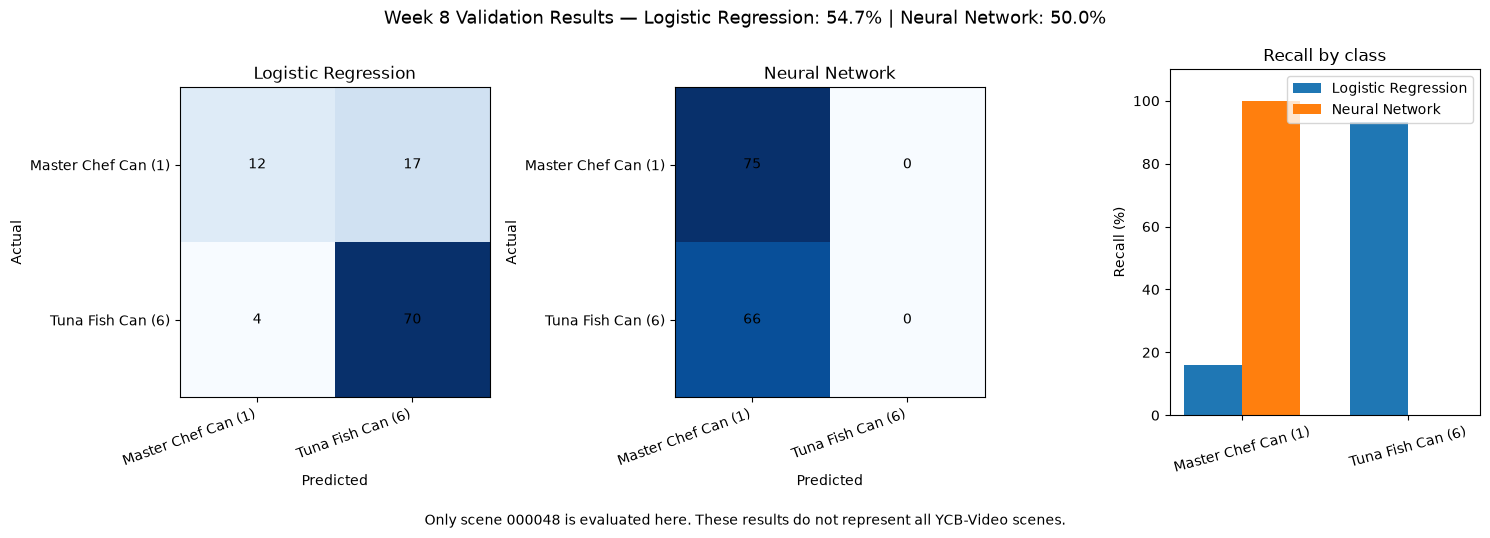

WEEK 8 VALIDATION DIAGNOSTIC
Validation scene: 000048

Logistic Regression accuracy: 54.67%
Neural Network accuracy: 50.00%

Validation true classes: Master Chef Can (1), Tuna Fish Can (6).
Confusion matrices use rows=true classes and columns=predicted classes.
This is a single-scene diagnostic, not a final overall performance estimate.

Image saved to: /Users/mac/Documents/MLInternship_week8/results/week8_validation_diagnostic.png
Report saved to: /Users/mac/Documents/MLInternship_week8/results/week8_validation_diagnostic.txt


In [36]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score

results_dir = Path("/Users/mac/Documents/MLInternship_week8/results")
results_dir.mkdir(parents=True, exist_ok=True)

# Current predictions
model.eval()
with torch.no_grad():
    nn_encoded = model(X_val_tensor).argmax(dim=1).cpu().numpy()

nn_pred = np.array([index_to_class[int(i)] for i in nn_encoded])
lr_pred = baseline.predict(X_val)

classes = [1, 6]
names = ["Master Chef Can (1)", "Tuna Fish Can (6)"]

predictions = {
    "Logistic Regression": lr_pred,
    "Neural Network": nn_pred
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, pred) in zip(axes[:2], predictions.items()):
    cm = confusion_matrix(y_val, pred, labels=classes)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks([0, 1], names, rotation=20, ha="right")
    ax.set_yticks([0, 1], names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

x = np.arange(2)
width = 0.35

for offset, (name, pred) in zip([-width / 2, width / 2], predictions.items()):
    recalls = [
        recall_score(y_val == c, pred == c, zero_division=0)
        for c in classes
    ]
    axes[2].bar(x + offset, np.array(recalls) * 100, width, label=name)

axes[2].set_xticks(x, names, rotation=15)
axes[2].set_ylim(0, 110)
axes[2].set_ylabel("Recall (%)")
axes[2].set_title("Recall by class")
axes[2].legend()

lr_acc = accuracy_score(y_val, lr_pred)
nn_acc = accuracy_score(y_val, nn_pred)

fig.suptitle(
    f"Week 8 Validation Results — Logistic Regression: {lr_acc:.1%} | Neural Network: {nn_acc:.1%}",
    fontsize=13
)
fig.text(
    0.5, -0.05,
    "Only scene 000048 is evaluated here. These results do not represent all YCB-Video scenes.",
    ha="center", fontsize=10
)
plt.tight_layout()

image_path = results_dir / "week8_validation_diagnostic.png"
plt.savefig(image_path, dpi=200, bbox_inches="tight")
plt.show()

report = (
    "WEEK 8 VALIDATION DIAGNOSTIC\n"
    "Validation scene: 000048\n\n"
    f"Logistic Regression accuracy: {lr_acc:.2%}\n"
    f"Neural Network accuracy: {nn_acc:.2%}\n\n"
    "Validation true classes: Master Chef Can (1), Tuna Fish Can (6).\n"
    "Confusion matrices use rows=true classes and columns=predicted classes.\n"
    "This is a single-scene diagnostic, not a final overall performance estimate."
)

report_path = results_dir / "week8_validation_diagnostic.txt"
report_path.write_text(report, encoding="utf-8")

print(report)
print(f"\nImage saved to: {image_path}")
print(f"Report saved to: {report_path}")

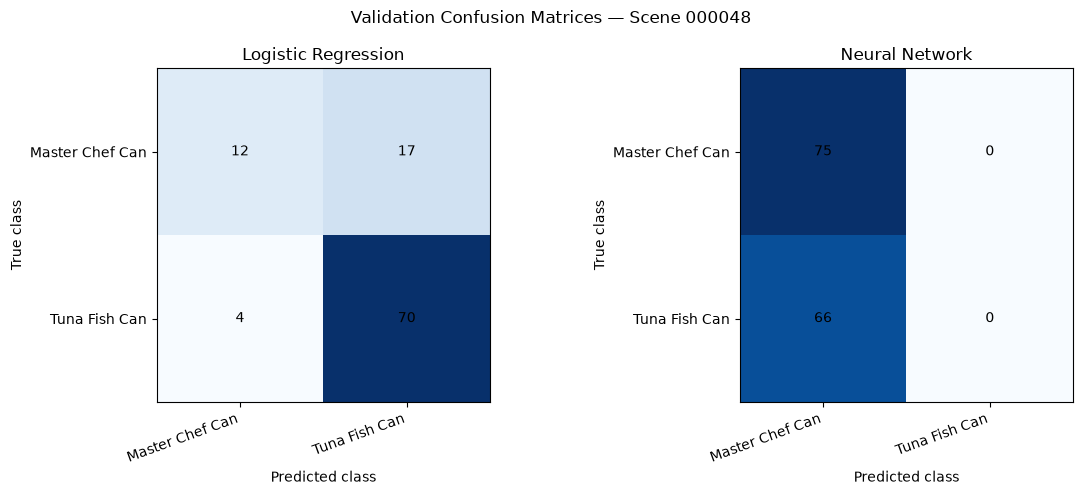

WEEK 8 — PER-CLASS VALIDATION ANALYSIS
Scene: 000048


Logistic Regression
Accuracy: 54.67%
                 precision    recall  f1-score   support

Master Chef Can       0.75      0.16      0.26        75
  Tuna Fish Can       0.80      0.93      0.86        75

      micro avg       0.80      0.55      0.65       150
      macro avg       0.78      0.55      0.56       150
   weighted avg       0.78      0.55      0.56       150


Neural Network
Accuracy: 50.00%
                 precision    recall  f1-score   support

Master Chef Can       0.53      1.00      0.69        75
  Tuna Fish Can       0.00      0.00      0.00        75

      micro avg       0.53      0.50      0.52       150
      macro avg       0.27      0.50      0.35       150
   weighted avg       0.27      0.50      0.35       150


Image saved to: /Users/mac/Documents/MLInternship_week8/results/week8_per_class_analysis.png
Report saved to: /Users/mac/Documents/MLInternship_week8/results/week8_per_class_analysis.t

In [37]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

results_dir = Path(
    "/Users/mac/Documents/MLInternship_week8/results"
)
results_dir.mkdir(parents=True, exist_ok=True)

class_ids = [1, 6]
class_names = ["Master Chef Can", "Tuna Fish Can"]

# Refresh current predictions
model.eval()
with torch.no_grad():
    nn_encoded = model(X_val_tensor).argmax(dim=1).cpu().numpy()

nn_pred = np.array([
    index_to_class[int(i)] for i in nn_encoded
])
lr_pred = baseline.predict(X_val)

models = {
    "Logistic Regression": lr_pred,
    "Neural Network": nn_pred
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
report_parts = ["WEEK 8 — PER-CLASS VALIDATION ANALYSIS", "Scene: 000048\n"]

for ax, (name, pred) in zip(axes, models.items()):
    cm = confusion_matrix(y_val, pred, labels=class_ids)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xticks([0, 1], class_names, rotation=20, ha="right")
    ax.set_yticks([0, 1], class_names)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")

    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    report_parts.append(f"\n{name}")
    report_parts.append(f"Accuracy: {accuracy_score(y_val, pred):.2%}")
    report_parts.append(
        classification_report(
            y_val,
            pred,
            labels=class_ids,
            target_names=class_names,
            zero_division=0
        )
    )

plt.suptitle("Validation Confusion Matrices — Scene 000048")
plt.tight_layout()

image_path = results_dir / "week8_per_class_analysis.png"
plt.savefig(image_path, dpi=200, bbox_inches="tight")
plt.show()

report_text = "\n".join(report_parts)
report_path = results_dir / "week8_per_class_analysis.txt"
report_path.write_text(report_text, encoding="utf-8")

print(report_text)
print(f"\nImage saved to: {image_path}")
print(f"Report saved to: {report_path}")

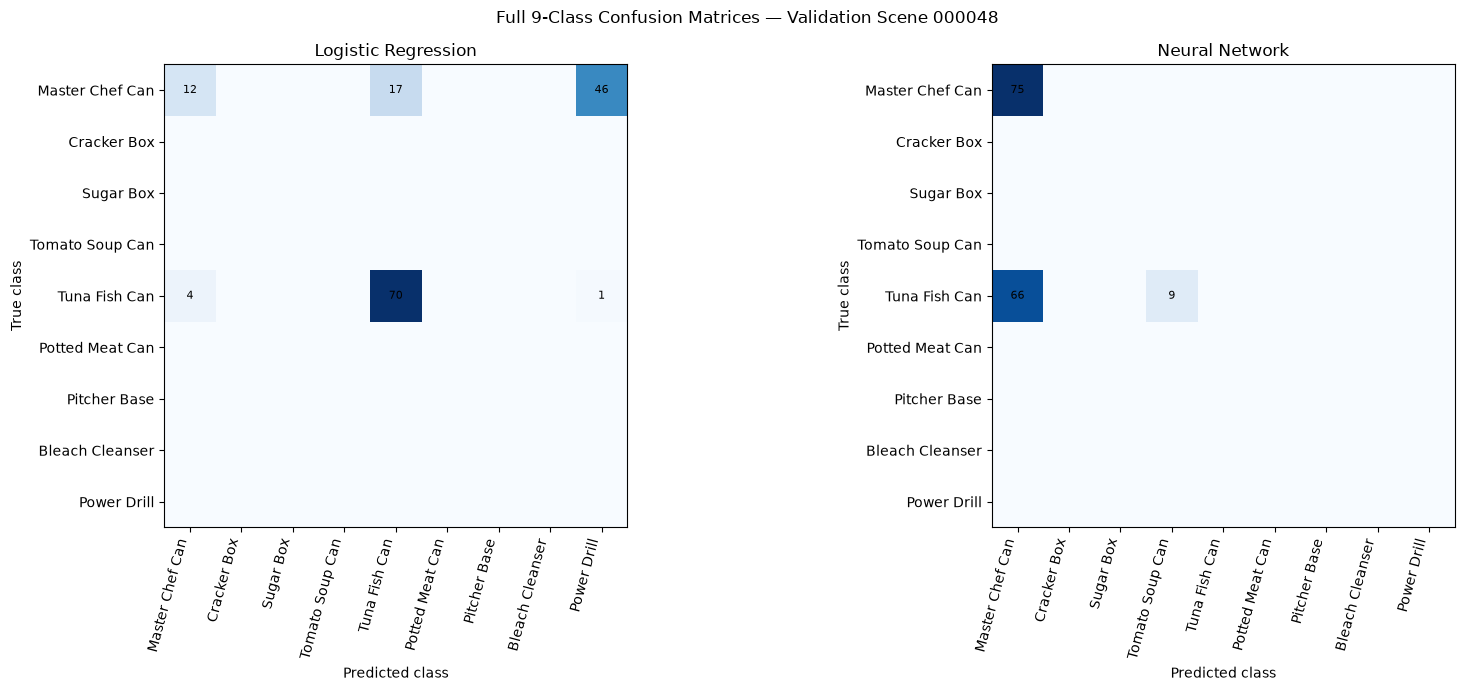

WEEK 8 — FULL 9-CLASS VALIDATION ANALYSIS
Validation scene: 000048
Note: this scene contains only Master Chef Can and Tuna Fish Can.

Logistic Regression
Accuracy: 54.67%
Predicted class counts: {1: 16, 6: 87, 15: 47}

Full 9-class classification report:
                 precision    recall  f1-score   support

Master Chef Can       0.75      0.16      0.26        75
    Cracker Box       0.00      0.00      0.00         0
      Sugar Box       0.00      0.00      0.00         0
Tomato Soup Can       0.00      0.00      0.00         0
  Tuna Fish Can       0.80      0.93      0.86        75
Potted Meat Can       0.00      0.00      0.00         0
   Pitcher Base       0.00      0.00      0.00         0
Bleach Cleanser       0.00      0.00      0.00         0
    Power Drill       0.00      0.00      0.00         0

       accuracy                           0.55       150
      macro avg       0.17      0.12      0.13       150
   weighted avg       0.78      0.55      0.56       150

F

In [38]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from collections import Counter

results_dir = Path("/Users/mac/Documents/MLInternship_week8/results")
results_dir.mkdir(parents=True, exist_ok=True)

class_ids = [1, 2, 3, 4, 6, 9, 11, 12, 15]
class_names = [
    "Master Chef Can",
    "Cracker Box",
    "Sugar Box",
    "Tomato Soup Can",
    "Tuna Fish Can",
    "Potted Meat Can",
    "Pitcher Base",
    "Bleach Cleanser",
    "Power Drill"
]

# Refresh predictions from both models
baseline_pred = baseline.predict(X_val)

model.eval()
with torch.no_grad():
    nn_encoded = model(X_val_tensor).argmax(dim=1).cpu().numpy()

nn_pred = np.array([index_to_class[int(i)] for i in nn_encoded])

models = {
    "Logistic Regression": baseline_pred,
    "Neural Network": nn_pred
}

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
report_parts = [
    "WEEK 8 — FULL 9-CLASS VALIDATION ANALYSIS",
    "Validation scene: 000048",
    "Note: this scene contains only Master Chef Can and Tuna Fish Can."
]

for ax, (model_name, predictions) in zip(axes, models.items()):
    cm = confusion_matrix(y_val, predictions, labels=class_ids)

    image = ax.imshow(cm, cmap="Blues")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(len(class_names)), class_names, rotation=75, ha="right")
    ax.set_yticks(range(len(class_names)), class_names)

    # Annotate all cells, including predictions into wrong classes
    for i in range(len(class_ids)):
        for j in range(len(class_ids)):
            if cm[i, j] > 0:
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)

    report_parts.extend([
        f"\n{'=' * 55}",
        model_name,
        f"Accuracy: {accuracy_score(y_val, predictions):.2%}",
        f"Predicted class counts: {dict(Counter(predictions))}",
        "\nFull 9-class classification report:",
        classification_report(
            y_val,
            predictions,
            labels=class_ids,
            target_names=class_names,
            zero_division=0
        ),
        "Full confusion matrix (rows=true, columns=predicted):",
        str(cm)
    ])

plt.suptitle("Full 9-Class Confusion Matrices — Validation Scene 000048")
plt.tight_layout()

image_path = results_dir / "week8_full_confusion_matrices.png"
plt.savefig(image_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

report_text = "\n".join(report_parts)
report_path = results_dir / "week8_full_class_report.txt"
report_path.write_text(report_text, encoding="utf-8")

print(report_text)
print(f"\nImage saved to: {image_path}")
print(f"Report saved to: {report_path}")


In [39]:

import numpy as np
from collections import Counter

class_names_by_id = {
    1: "Master Chef Can",
    2: "Cracker Box",
    3: "Sugar Box",
    4: "Tomato Soup Can",
    6: "Tuna Fish Can",
    9: "Potted Meat Can",
    11: "Pitcher Base",
    12: "Bleach Cleanser",
    15: "Power Drill"
}

print("CLASS COVERAGE BY SCENE — excluding test scene 000059")
print("=" * 72)

scene_values = np.asarray(groups).astype(int)
labels = np.asarray(y).astype(int)

for scene_id in range(48, 59):
    mask = scene_values == scene_id
    scene_labels = labels[mask]
    counts = Counter(scene_labels)

    print(f"\nScene {scene_id:06d} | samples: {len(scene_labels)}")
    print(f"Classes present: {len(counts)} / {len(class_names_by_id)}")

    for class_id, name in class_names_by_id.items():
        count = counts.get(class_id, 0)
        if count > 0:
            print(f"  {class_id:>2} — {name}: {count}")


CLASS COVERAGE BY SCENE — excluding test scene 000059

Scene 000048 | samples: 150
Classes present: 2 / 9
   1 — Master Chef Can: 75
   6 — Tuna Fish Can: 75

Scene 000049 | samples: 225
Classes present: 3 / 9
   3 — Sugar Box: 75
   6 — Tuna Fish Can: 75
   9 — Potted Meat Can: 75

Scene 000050 | samples: 225
Classes present: 3 / 9
   2 — Cracker Box: 75
   4 — Tomato Soup Can: 75
  15 — Power Drill: 75

Scene 000051 | samples: 300
Classes present: 4 / 9
   1 — Master Chef Can: 75
   3 — Sugar Box: 75
   4 — Tomato Soup Can: 75
  12 — Bleach Cleanser: 75

Scene 000052 | samples: 150
Classes present: 2 / 9
   6 — Tuna Fish Can: 75
  11 — Pitcher Base: 75

Scene 000053 | samples: 150
Classes present: 2 / 9
   4 — Tomato Soup Can: 75
   9 — Potted Meat Can: 75

Scene 000054 | samples: 300
Classes present: 4 / 9
   2 — Cracker Box: 75
   3 — Sugar Box: 75
  12 — Bleach Cleanser: 75
  15 — Power Drill: 75

Scene 000055 | samples: 300
Classes present: 4 / 9
   1 — Master Chef Can: 75
   3 —

Fold 01/11 | held-out scene 000048 | samples: 150 | LR acc: 54.67% | NN acc: 50.00%
Fold 02/11 | held-out scene 000049 | samples: 225 | LR acc: 49.33% | NN acc: 52.44%
Fold 03/11 | held-out scene 000050 | samples: 225 | LR acc: 64.00% | NN acc: 66.67%
Fold 04/11 | held-out scene 000051 | samples: 300 | LR acc: 55.33% | NN acc: 70.33%
Fold 05/11 | held-out scene 000052 | samples: 150 | LR acc: 98.67% | NN acc: 98.00%
Fold 06/11 | held-out scene 000053 | samples: 150 | LR acc: 24.00% | NN acc: 24.00%
Fold 07/11 | held-out scene 000054 | samples: 300 | LR acc: 75.00% | NN acc: 82.33%
Fold 08/11 | held-out scene 000055 | samples: 300 | LR acc: 93.00% | NN acc: 97.67%
Fold 09/11 | held-out scene 000056 | samples: 225 | LR acc: 99.11% | NN acc: 100.00%
Fold 10/11 | held-out scene 000057 | samples: 150 | LR acc: 90.67% | NN acc: 81.33%
Fold 11/11 | held-out scene 000058 | samples: 150 | LR acc: 87.33% | NN acc: 90.67%


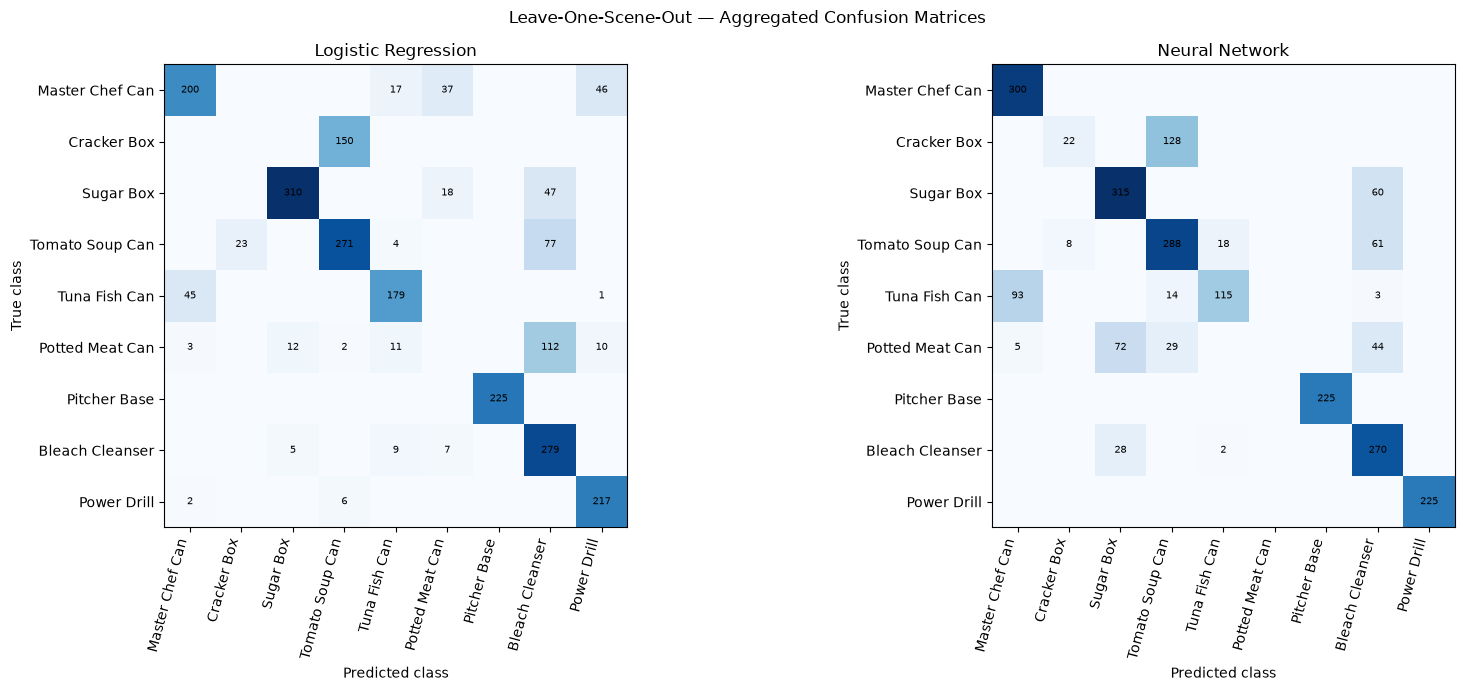


WEEK 8 — LEAVE-ONE-SCENE-OUT CROSS-VALIDATION
Scenes: 000048–000058
Scene 000059 was excluded and remains reserved for final testing.
Neural Network epochs per fold: 5

These are aggregated out-of-fold predictions; each scene was held out in turn.

Logistic Regression
Overall out-of-fold accuracy: 72.30%
Macro F1: 0.6271

Classification report:
                 precision    recall  f1-score   support

Master Chef Can       0.80      0.67      0.73       300
    Cracker Box       0.00      0.00      0.00       150
      Sugar Box       0.95      0.83      0.88       375
Tomato Soup Can       0.63      0.72      0.67       375
  Tuna Fish Can       0.81      0.80      0.80       225
Potted Meat Can       0.00      0.00      0.00       150
   Pitcher Base       1.00      1.00      1.00       225
Bleach Cleanser       0.54      0.93      0.68       300
    Power Drill       0.79      0.96      0.87       225

       accuracy                           0.72      2325
      macro avg       0

In [40]:

from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Keep scene 000059 completely reserved for the final test
X_all = np.asarray(X_color, dtype=np.float32)
y_all = np.asarray(y).astype(int)
groups_all = np.asarray(groups).astype(int)

class_ids = [1, 2, 3, 4, 6, 9, 11, 12, 15]
class_names = [
    "Master Chef Can", "Cracker Box", "Sugar Box",
    "Tomato Soup Can", "Tuna Fish Can", "Potted Meat Can",
    "Pitcher Base", "Bleach Cleanser", "Power Drill"
]

development_mask = groups_all != 59
X_dev = X_all[development_mask]
y_dev = y_all[development_mask]
groups_dev = groups_all[development_mask]

logo = LeaveOneGroupOut()
lr_oof = np.full(len(y_dev), -1, dtype=int)
nn_oof = np.full(len(y_dev), -1, dtype=int)

device = torch.device("cpu")
epochs_per_fold = 5

for fold, (train_idx, val_idx) in enumerate(
    logo.split(X_dev, y_dev, groups_dev), start=1
):
    held_out_scene = int(groups_dev[val_idx][0])

    X_tr, X_va = X_dev[train_idx], X_dev[val_idx]
    y_tr, y_va = y_dev[train_idx], y_dev[val_idx]

    # Logistic Regression baseline
    lr = LogisticRegression(max_iter=1000, random_state=42)
    lr.fit(X_tr, y_tr)
    lr_oof[val_idx] = lr.predict(X_va)

    # Neural Network: same architecture, freshly initialized per fold
    torch.manual_seed(42)

    class_to_index_local = {class_id: i for i, class_id in enumerate(class_ids)}
    y_tr_encoded = np.array([class_to_index_local[v] for v in y_tr])
    y_va_encoded = np.array([class_to_index_local[v] for v in y_va])

    X_tr_t = torch.tensor(X_tr, dtype=torch.float32)
    y_tr_t = torch.tensor(y_tr_encoded, dtype=torch.long)
    X_va_t = torch.tensor(X_va, dtype=torch.float32)

    loader = DataLoader(
        TensorDataset(X_tr_t, y_tr_t),
        batch_size=64,
        shuffle=True
    )

    fold_model = YCBVNeuralNetwork(
        input_size=X_dev.shape[1],
        hidden_size=128,
        num_classes=len(class_ids)
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(fold_model.parameters(), lr=0.001)

    for epoch in range(epochs_per_fold):
        fold_model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            logits = fold_model(xb.to(device))
            loss = criterion(logits, yb.to(device))
            loss.backward()
            optimizer.step()

    fold_model.eval()
    with torch.no_grad():
        nn_encoded_pred = fold_model(X_va_t).argmax(dim=1).cpu().numpy()

    nn_oof[val_idx] = np.array([
        class_ids[i] for i in nn_encoded_pred
    ])

    print(
        f"Fold {fold:02d}/11 | held-out scene {held_out_scene:06d} | "
        f"samples: {len(val_idx)} | "
        f"LR acc: {accuracy_score(y_va, lr_oof[val_idx]):.2%} | "
        f"NN acc: {accuracy_score(y_va, nn_oof[val_idx]):.2%}"
    )

# Aggregate out-of-fold results across all 11 development scenes
results_dir = Path(
    "/Users/mac/Documents/MLInternship_week8/results"
)
results_dir.mkdir(parents=True, exist_ok=True)

report_parts = [
    "WEEK 8 — LEAVE-ONE-SCENE-OUT CROSS-VALIDATION",
    "Scenes: 000048–000058",
    "Scene 000059 was excluded and remains reserved for final testing.",
    f"Neural Network epochs per fold: {epochs_per_fold}",
    "\nThese are aggregated out-of-fold predictions; each scene was held out in turn."
]

for name, predictions in [
    ("Logistic Regression", lr_oof),
    ("Neural Network", nn_oof)
]:
    accuracy = accuracy_score(y_dev, predictions)
    macro_f1 = f1_score(
        y_dev, predictions, labels=class_ids,
        average="macro", zero_division=0
    )

    report_parts.extend([
        f"\n{'=' * 55}",
        name,
        f"Overall out-of-fold accuracy: {accuracy:.2%}",
        f"Macro F1: {macro_f1:.4f}",
        "\nClassification report:",
        classification_report(
            y_dev,
            predictions,
            labels=class_ids,
            target_names=class_names,
            zero_division=0
        )
    ])

# Plot full out-of-fold confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, (name, predictions) in zip(
    axes,
    [("Logistic Regression", lr_oof), ("Neural Network", nn_oof)]
):
    cm = confusion_matrix(y_dev, predictions, labels=class_ids)
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(len(class_names)), class_names, rotation=75, ha="right")
    ax.set_yticks(range(len(class_names)), class_names)

    for i in range(len(class_ids)):
        for j in range(len(class_ids)):
            if cm[i, j] > 0:
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=7)

plt.suptitle("Leave-One-Scene-Out — Aggregated Confusion Matrices")
plt.tight_layout()

image_path = results_dir / "week8_grouped_cv_confusion_matrices.png"
plt.savefig(image_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

report_text = "\n".join(report_parts)
report_path = results_dir / "week8_grouped_cv_report.txt"
report_path.write_text(report_text, encoding="utf-8")

print("\n" + report_text)
print(f"\nImage saved to: {image_path}")
print(f"Report saved to: {report_path}")


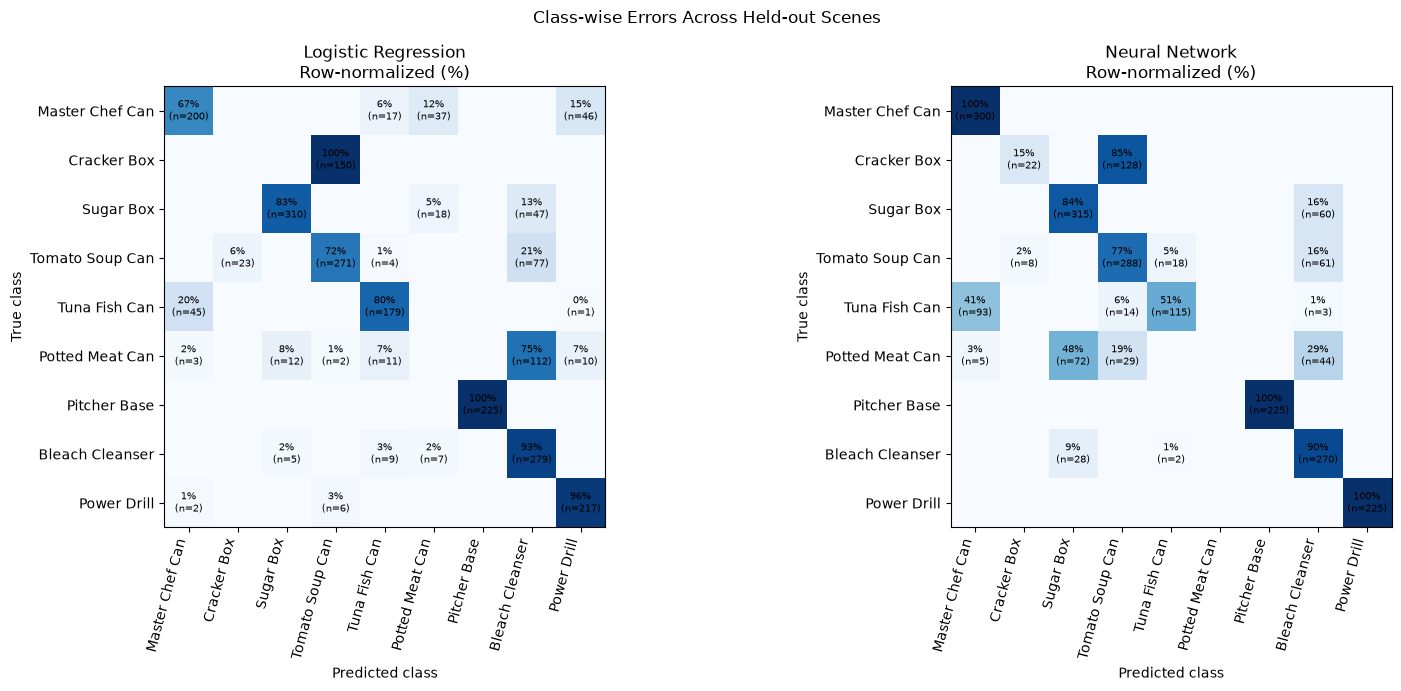

WEEK 8 — CLASS CONFUSION INVESTIGATION

Logistic Regression

Master Chef Can (ID 1): 200/300 correct (66.7% recall)
  Most common errors: Power Drill: 46, Potted Meat Can: 37, Tuna Fish Can: 17

Cracker Box (ID 2): 0/150 correct (0.0% recall)
  Most common errors: Tomato Soup Can: 150

Sugar Box (ID 3): 310/375 correct (82.7% recall)
  Most common errors: Bleach Cleanser: 47, Potted Meat Can: 18

Tomato Soup Can (ID 4): 271/375 correct (72.3% recall)
  Most common errors: Bleach Cleanser: 77, Cracker Box: 23, Tuna Fish Can: 4

Tuna Fish Can (ID 6): 179/225 correct (79.6% recall)
  Most common errors: Master Chef Can: 45, Power Drill: 1

Potted Meat Can (ID 9): 0/150 correct (0.0% recall)
  Most common errors: Bleach Cleanser: 112, Sugar Box: 12, Tuna Fish Can: 11

Pitcher Base (ID 11): 225/225 correct (100.0% recall)
  No misclassifications in these predictions.

Bleach Cleanser (ID 12): 279/300 correct (93.0% recall)
  Most common errors: Tuna Fish Can: 9, Potted Meat Can: 7, Sugar Bo

In [41]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

class_ids = [1, 2, 3, 4, 6, 9, 11, 12, 15]
class_names = [
    "Master Chef Can", "Cracker Box", "Sugar Box",
    "Tomato Soup Can", "Tuna Fish Can", "Potted Meat Can",
    "Pitcher Base", "Bleach Cleanser", "Power Drill"
]

results_dir = Path("/Users/mac/Documents/MLInternship_week8/results")
results_dir.mkdir(parents=True, exist_ok=True)

model_predictions = {
    "Logistic Regression": lr_oof,
    "Neural Network": nn_oof
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
report = ["WEEK 8 — CLASS CONFUSION INVESTIGATION"]

for ax, (model_name, predictions) in zip(axes, model_predictions.items()):
    cm = confusion_matrix(y_dev, predictions, labels=class_ids)

    # Row-normalized matrix shows the proportion of each true class
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_percent = np.divide(
        cm, row_sums,
        out=np.zeros_like(cm, dtype=float),
        where=row_sums != 0
    ) * 100

    ax.imshow(cm_percent, cmap="Blues", vmin=0, vmax=100)
    ax.set_title(f"{model_name}\nRow-normalized (%)")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(len(class_names)), class_names, rotation=75, ha="right")
    ax.set_yticks(range(len(class_names)), class_names)

    for i in range(len(class_ids)):
        for j in range(len(class_ids)):
            if cm[i, j] > 0:
                ax.text(
                    j, i, f"{cm_percent[i, j]:.0f}%\n(n={cm[i, j]})",
                    ha="center", va="center", fontsize=7
                )

    report.append(f"\n{'=' * 55}\n{model_name}")

    for i, class_id in enumerate(class_ids):
        total = int(cm[i].sum())
        correct = int(cm[i, i])
        if total == 0:
            continue

        wrong = [
            (int(cm[i, j]), class_names[j])
            for j in range(len(class_ids))
            if j != i and cm[i, j] > 0
        ]
        wrong.sort(reverse=True)

        report.append(
            f"\n{class_names[i]} (ID {class_id}): "
            f"{correct}/{total} correct ({correct / total:.1%} recall)"
        )

        if wrong:
            report.append(
                "  Most common errors: " +
                ", ".join(f"{name}: {count}" for count, name in wrong[:3])
            )
        else:
            report.append("  No misclassifications in these predictions.")

plt.suptitle("Class-wise Errors Across Held-out Scenes")
plt.tight_layout()

image_path = results_dir / "week8_class_confusion_investigation.png"
plt.savefig(image_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

report_text = "\n".join(report)
report_path = results_dir / "week8_class_confusion_investigation.txt"
report_path.write_text(report_text, encoding="utf-8")

print(report_text)
print(f"\nImage saved to: {image_path}")
print(f"Report saved to: {report_path}")


In [42]:

from collections import Counter
import numpy as np

difficult_classes = {
    2: "Cracker Box",
    9: "Potted Meat Can"
}

print("DIFFICULT CLASS PERFORMANCE BY HELD-OUT SCENE")
print("=" * 65)

for scene_id in sorted(np.unique(groups_dev)):
    scene_mask = groups_dev == scene_id
    y_scene = y_dev[scene_mask]

    print(f"\nScene {scene_id:06d} | samples: {scene_mask.sum()}")

    for class_id, class_name in difficult_classes.items():
        class_mask = scene_mask & (y_dev == class_id)
        support = int(class_mask.sum())

        if support == 0:
            continue

        lr_correct = int((lr_oof[class_mask] == class_id).sum())
        nn_correct = int((nn_oof[class_mask] == class_id).sum())

        print(
            f"  {class_name}: "
            f"LR {lr_correct}/{support} ({lr_correct / support:.1%}) | "
            f"NN {nn_correct}/{support} ({nn_correct / support:.1%})"
        )

print("\nPredicted classes for each difficult true class:")
for class_id, class_name in difficult_classes.items():
    mask = y_dev == class_id
    print(f"\n{class_name} (ID {class_id}), true samples: {int(mask.sum())}")

    print("  Logistic Regression:", dict(Counter(lr_oof[mask])))
    print("  Neural Network:", dict(Counter(nn_oof[mask])))


DIFFICULT CLASS PERFORMANCE BY HELD-OUT SCENE

Scene 000048 | samples: 150

Scene 000049 | samples: 225
  Potted Meat Can: LR 0/75 (0.0%) | NN 0/75 (0.0%)

Scene 000050 | samples: 225
  Cracker Box: LR 0/75 (0.0%) | NN 0/75 (0.0%)

Scene 000051 | samples: 300

Scene 000052 | samples: 150

Scene 000053 | samples: 150
  Potted Meat Can: LR 0/75 (0.0%) | NN 0/75 (0.0%)

Scene 000054 | samples: 300
  Cracker Box: LR 0/75 (0.0%) | NN 22/75 (29.3%)

Scene 000055 | samples: 300

Scene 000056 | samples: 225

Scene 000057 | samples: 150

Scene 000058 | samples: 150

Predicted classes for each difficult true class:

Cracker Box (ID 2), true samples: 150
  Logistic Regression: {4: 150}
  Neural Network: {4: 128, 2: 22}

Potted Meat Can (ID 9), true samples: 150
  Logistic Regression: {15: 10, 1: 3, 12: 112, 3: 12, 4: 2, 6: 11}
  Neural Network: {3: 72, 4: 29, 12: 44, 1: 5}


Color — original          | Accuracy: 72.30% | Macro F1: 0.6271
Color — standardized      | Accuracy: 75.14% | Macro F1: 0.6907
HOG — standardized        | Accuracy: 20.17% | Macro F1: 0.1820
Combined — standardized   | Accuracy: 73.29% | Macro F1: 0.6803


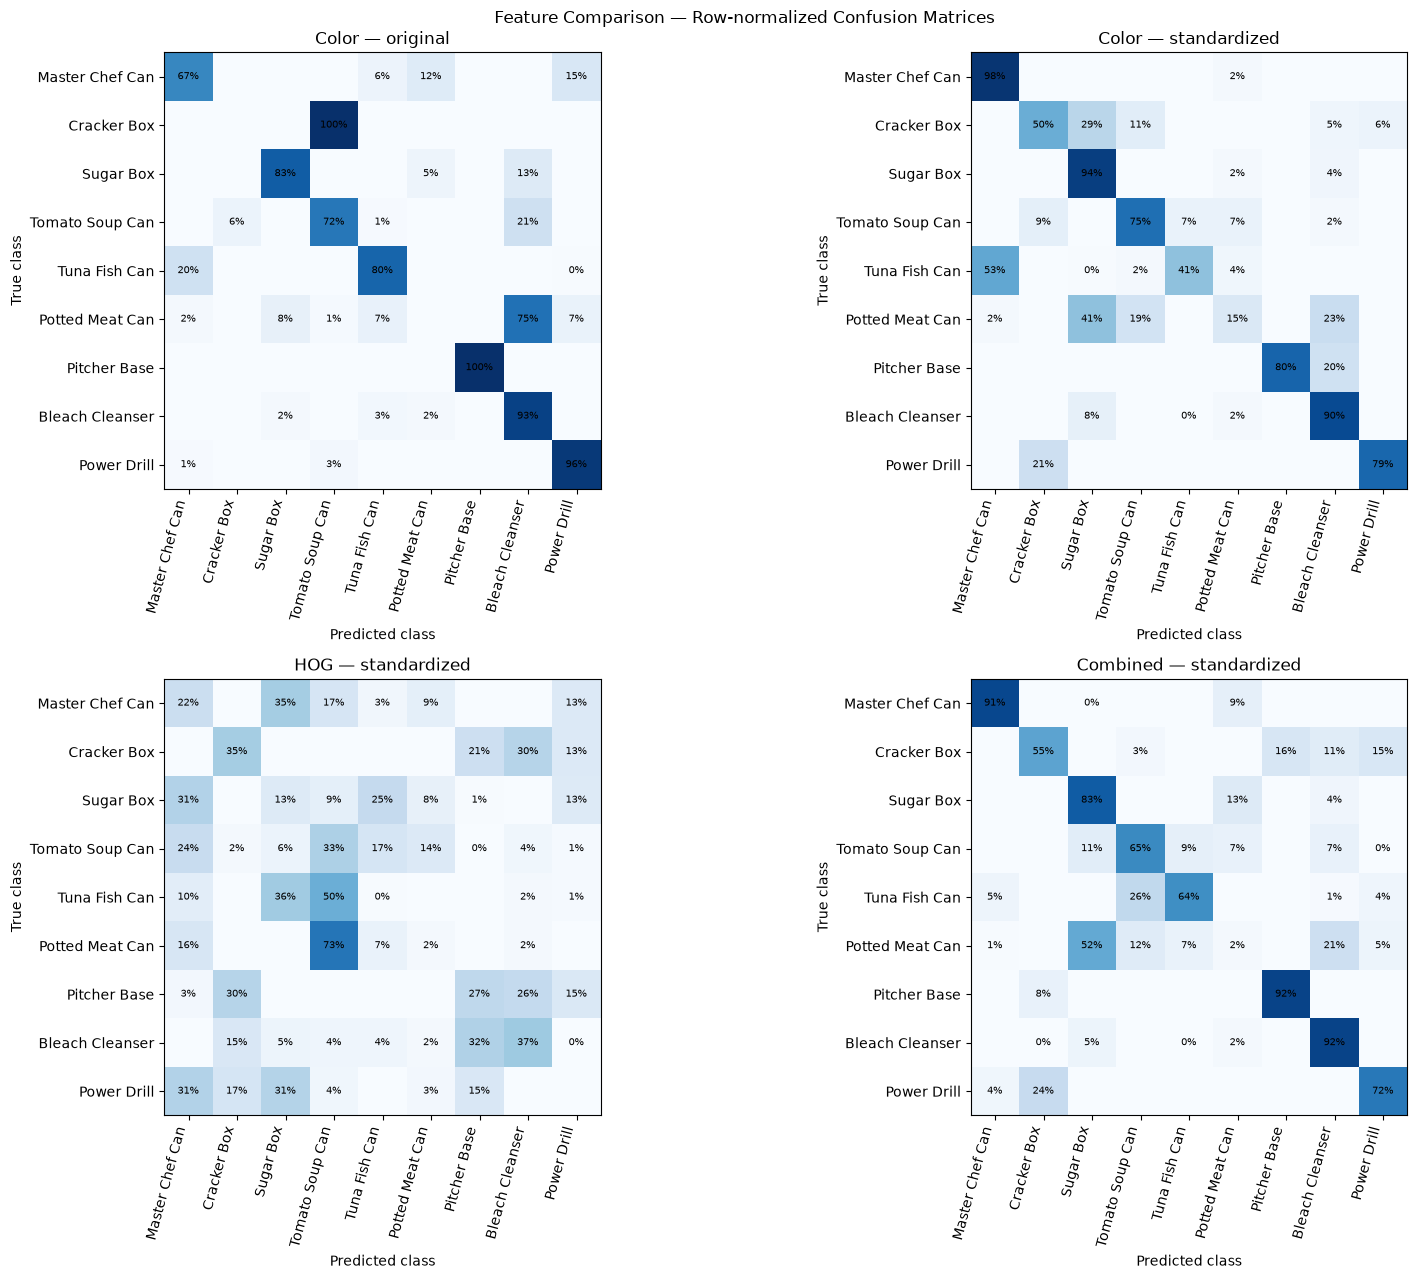


WEEK 8 — FEATURE REPRESENTATION ABLATION
Evaluation: Leave-One-Scene-Out, scenes 000048–000058
Final test scene 000059 excluded.

Color — original
Feature dimensions: 4096
Accuracy: 72.30%
Macro F1: 0.6271
Recall by class:
  Master Chef Can: 66.7%
  Cracker Box: 0.0%
  Sugar Box: 82.7%
  Tomato Soup Can: 72.3%
  Tuna Fish Can: 79.6%
  Potted Meat Can: 0.0%
  Pitcher Base: 100.0%
  Bleach Cleanser: 93.0%
  Power Drill: 96.4%

Color — standardized
Feature dimensions: 4096
Accuracy: 75.14%
Macro F1: 0.6907
Recall by class:
  Master Chef Can: 98.0%
  Cracker Box: 50.0%
  Sugar Box: 94.4%
  Tomato Soup Can: 75.5%
  Tuna Fish Can: 41.3%
  Potted Meat Can: 14.7%
  Pitcher Base: 80.0%
  Bleach Cleanser: 89.7%
  Power Drill: 78.7%

HOG — standardized
Feature dimensions: 1764
Accuracy: 20.17%
Macro F1: 0.1820
Recall by class:
  Master Chef Can: 22.3%
  Cracker Box: 35.3%
  Sugar Box: 13.1%
  Tomato Soup Can: 32.8%
  Tuna Fish Can: 0.4%
  Potted Meat Can: 2.0%
  Pitcher Base: 27.1%
  Bleach Clea

In [43]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# Keep the final test scene excluded
development_mask = np.asarray(groups).astype(int) != 59

y_dev = np.asarray(y).astype(int)[development_mask]
groups_dev = np.asarray(groups).astype(int)[development_mask]

feature_sets = {
    "Color — original": (
        np.asarray(X_color, dtype=np.float32)[development_mask],
        False
    ),
    "Color — standardized": (
        np.asarray(X_color, dtype=np.float32)[development_mask],
        True
    ),
    "HOG — standardized": (
        np.asarray(X_hog, dtype=np.float32)[development_mask],
        True
    ),
    "Combined — standardized": (
        np.asarray(X_combined, dtype=np.float32)[development_mask],
        True
    )
}

class_ids = [1, 2, 3, 4, 6, 9, 11, 12, 15]
class_names = [
    "Master Chef Can", "Cracker Box", "Sugar Box",
    "Tomato Soup Can", "Tuna Fish Can", "Potted Meat Can",
    "Pitcher Base", "Bleach Cleanser", "Power Drill"
]

logo = LeaveOneGroupOut()
all_predictions = {}
report_lines = [
    "WEEK 8 — FEATURE REPRESENTATION ABLATION",
    "Evaluation: Leave-One-Scene-Out, scenes 000048–000058",
    "Final test scene 000059 excluded."
]

for feature_name, (X_dev_features, use_scaling) in feature_sets.items():
    oof_pred = np.full(len(y_dev), -1, dtype=int)

    for train_idx, val_idx in logo.split(
        X_dev_features, y_dev, groups_dev
    ):
        if use_scaling:
            classifier = make_pipeline(
                StandardScaler(),
                LogisticRegression(max_iter=2000, random_state=42)
            )
        else:
            classifier = LogisticRegression(
                max_iter=2000, random_state=42
            )

        classifier.fit(
            X_dev_features[train_idx],
            y_dev[train_idx]
        )
        oof_pred[val_idx] = classifier.predict(
            X_dev_features[val_idx]
        )

    all_predictions[feature_name] = oof_pred

    accuracy = accuracy_score(y_dev, oof_pred)
    macro_f1 = f1_score(
        y_dev, oof_pred,
        labels=class_ids,
        average="macro",
        zero_division=0
    )

    report_lines.extend([
        f"\n{'=' * 55}",
        feature_name,
        f"Feature dimensions: {X_dev_features.shape[1]}",
        f"Accuracy: {accuracy:.2%}",
        f"Macro F1: {macro_f1:.4f}",
        "Recall by class:"
    ])

    cm = confusion_matrix(y_dev, oof_pred, labels=class_ids)
    row_totals = cm.sum(axis=1)

    for i, class_name in enumerate(class_names):
        recall = cm[i, i] / row_totals[i] if row_totals[i] else 0
        report_lines.append(f"  {class_name}: {recall:.1%}")

    print(
        f"{feature_name:25s} | "
        f"Accuracy: {accuracy:.2%} | Macro F1: {macro_f1:.4f}"
    )

# Plot all four confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(17, 13))

for ax, (feature_name, predictions) in zip(
    axes.flat, all_predictions.items()
):
    cm = confusion_matrix(y_dev, predictions, labels=class_ids)
    row_totals = cm.sum(axis=1, keepdims=True)
    cm_percent = np.divide(
        cm, row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0
    ) * 100

    ax.imshow(cm_percent, cmap="Blues", vmin=0, vmax=100)
    ax.set_title(feature_name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(len(class_names)), class_names, rotation=75, ha="right")
    ax.set_yticks(range(len(class_names)), class_names)

    for i in range(len(class_ids)):
        for j in range(len(class_ids)):
            if cm[i, j] > 0:
                ax.text(
                    j, i, f"{cm_percent[i, j]:.0f}%",
                    ha="center", va="center", fontsize=7
                )

plt.suptitle("Feature Comparison — Row-normalized Confusion Matrices")
plt.tight_layout()

results_dir = Path(
    "/Users/mac/Documents/MLInternship_week8/results"
)
results_dir.mkdir(parents=True, exist_ok=True)

image_path = results_dir / "week8_feature_ablation.png"
plt.savefig(image_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

report_text = "\n".join(report_lines)
report_path = results_dir / "week8_feature_ablation.txt"
report_path.write_text(report_text, encoding="utf-8")

print("\n" + report_text)
print(f"\nImage saved to: {image_path}")
print(f"Report saved to: {report_path}")
